In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import joblib

# Đọc dữ liệu gốc (có cột nhạy cảm personal_status, foreign_worker)
df_clean = pd.read_csv('../data/processed/german_clean.csv')

# Đọc dữ liệu đã tiền xử lý (dùng cho mô hình)
train = pd.read_csv('../data/processed/train.csv')
val = pd.read_csv('../data/processed/val.csv')
test = pd.read_csv('../data/processed/test.csv')

# Tách X, y cho test
X_test = test.drop(columns=['target'])
y_test = test['target']

# Load preprocessor và mô hình đã huấn luyện
preprocessor = joblib.load('../data/processed/preprocessor.pkl')

# Huấn luyện lại LogReg trên train (để có mô hình trong notebook này)
X_train = train.drop(columns=['target'])
y_train = train['target']
lr = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
lr.fit(X_train, y_train)

# Dự đoán trên test
y_test_proba = lr.predict_proba(X_test)[:, 1]
optimal_threshold = 0.70
y_test_pred = (y_test_proba >= optimal_threshold).astype(int)

print("Đã load dữ liệu và mô hình")
print(f"Test set: {X_test.shape}")
print(f"Số dự đoán Good (duyệt): {y_test_pred.sum()}")
print(f"Số dự đoán Bad (từ chối): {(1-y_test_pred).sum()}")

Đã load dữ liệu và mô hình
Test set: (200, 61)
Số dự đoán Good (duyệt): 83
Số dự đoán Bad (từ chối): 117


In [2]:
# Lấy chỉ số của các dòng trong test set (để map với dữ liệu gốc)
# Vì test được chia từ df_clean với random_state=42, ta cần lấy lại đúng chỉ số
from sklearn.model_selection import train_test_split

# Tái tạo lại quá trình chia để lấy chỉ số
drop_cols = [c for c in df_clean.columns if c.endswith('_label')] + ['credit_risk']
X_full = df_clean.drop(columns=drop_cols)
y_full = df_clean['credit_risk'].map({1: 1, 2: 0})

# Chia lại y hệt như bước preprocessing
_, X_temp_idx, _, y_temp = train_test_split(
    X_full, y_full, test_size=0.4, stratify=y_full, random_state=42
)
X_val_idx, X_test_idx, _, _ = train_test_split(
    X_temp_idx, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)

# Lấy dữ liệu gốc của test set (có cột nhạy cảm)
test_original = df_clean.loc[X_test_idx.index].copy()
test_original['y_pred'] = y_test_pred
test_original['y_proba'] = y_test_proba

print("Đã map test set với dữ liệu gốc")
print(f"Số dòng test: {len(test_original)}")
print("\nPhân bố giới tính (từ personal_status_label):")
print(test_original['personal_status_label'].value_counts())

Đã map test set với dữ liệu gốc
Số dòng test: 200

Phân bố giới tính (từ personal_status_label):
personal_status_label
male single                          121
female divorced/separated/married     51
male married/widowed                  17
male divorced/separated               11
Name: count, dtype: int64


In [3]:
# Tạo cột giới tính từ personal_status
def get_gender(status):
    if status in ['male divorced/separated', 'male single', 'male married/widowed']:
        return 'Male'
    else:
        return 'Female'

test_original['gender'] = test_original['personal_status_label'].apply(get_gender)
test_original['foreign_worker_bin'] = test_original['foreign_worker_label']

print("=== TỶ LỆ DUYỆT THEO GIỚI TÍNH ===")
for gender in ['Male', 'Female']:
    subset = test_original[test_original['gender'] == gender]
    approval_rate = subset['y_pred'].mean()
    n = len(subset)
    print(f"{gender}: {approval_rate:.1%} duyệt (n={n})")

print("\n=== TỶ LỆ DUYỆT THEO LAO ĐỘNG NƯỚC NGOÀI ===")
for fw in ['yes', 'no']:
    subset = test_original[test_original['foreign_worker_bin'] == fw]
    if len(subset) > 0:
        approval_rate = subset['y_pred'].mean()
        n = len(subset)
        print(f"Foreign worker = {fw}: {approval_rate:.1%} duyệt (n={n})")

print("\n=== FALSE NEGATIVE RATE (FNR) THEO GIỚI TÍNH ===")
print("FNR = trong số người THỰC SỰ TỐT, bao nhiêu bị từ chối oan?")
for gender in ['Male', 'Female']:
    subset = test_original[(test_original['gender'] == gender) & (test_original['target'] == 1)]
    if len(subset) > 0:
        fnr = (subset['y_pred'] == 0).mean()
        print(f"{gender}: FNR = {fnr:.1%} (n={len(subset)} người thực sự Tốt)")

=== TỶ LỆ DUYỆT THEO GIỚI TÍNH ===
Male: 42.3% duyệt (n=149)
Female: 39.2% duyệt (n=51)

=== TỶ LỆ DUYỆT THEO LAO ĐỘNG NƯỚC NGOÀI ===
Foreign worker = yes: 40.1% duyệt (n=192)
Foreign worker = no: 75.0% duyệt (n=8)

=== FALSE NEGATIVE RATE (FNR) THEO GIỚI TÍNH ===
FNR = trong số người THỰC SỰ TỐT, bao nhiêu bị từ chối oan?


KeyError: 'target'

In [4]:
# SỬA LỖI: Thêm cột target vào test_original
test_original['target'] = y_test.values

print("=== FALSE NEGATIVE RATE (FNR) THEO GIỚI TÍNH ===")
print("FNR = trong số người THỰC SỰ TỐT, bao nhiêu bị từ chối oan?\n")

for gender in ['Male', 'Female']:
    subset = test_original[(test_original['gender'] == gender) & (test_original['target'] == 1)]
    if len(subset) > 0:
        fnr = (subset['y_pred'] == 0).mean()
        print(f"{gender}: FNR = {fnr:.1%} (n={len(subset)} người thực sự Tốt)")

print("\n=== FALSE NEGATIVE RATE (FNR) THEO LAO ĐỘNG NƯỚC NGOÀI ===")
for fw in ['yes', 'no']:
    subset = test_original[(test_original['foreign_worker_bin'] == fw) & (test_original['target'] == 1)]
    if len(subset) > 0:
        fnr = (subset['y_pred'] == 0).mean()
        print(f"Foreign worker = {fw}: FNR = {fnr:.1%} (n={len(subset)} người thực sự Tốt)")

# Bảng tổng hợp
print("\n=== BẢNG TỔNG HỢP ===")
summary = []
for gender in ['Male', 'Female']:
    subset = test_original[test_original['gender'] == gender]
    approval = subset['y_pred'].mean()
    subset_good = subset[subset['target'] == 1]
    fnr = (subset_good['y_pred'] == 0).mean() if len(subset_good) > 0 else np.nan
    summary.append({'group': gender, 'n': len(subset), 'approval_rate': approval, 'FNR': fnr})

summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))

=== FALSE NEGATIVE RATE (FNR) THEO GIỚI TÍNH ===
FNR = trong số người THỰC SỰ TỐT, bao nhiêu bị từ chối oan?

Male: FNR = 46.2% (n=106 người thực sự Tốt)
Female: FNR = 47.1% (n=34 người thực sự Tốt)

=== FALSE NEGATIVE RATE (FNR) THEO LAO ĐỘNG NƯỚC NGOÀI ===
Foreign worker = yes: FNR = 48.1% (n=133 người thực sự Tốt)
Foreign worker = no: FNR = 14.3% (n=7 người thực sự Tốt)

=== BẢNG TỔNG HỢP ===
 group   n  approval_rate      FNR
  Male 149       0.422819 0.462264
Female  51       0.392157 0.470588


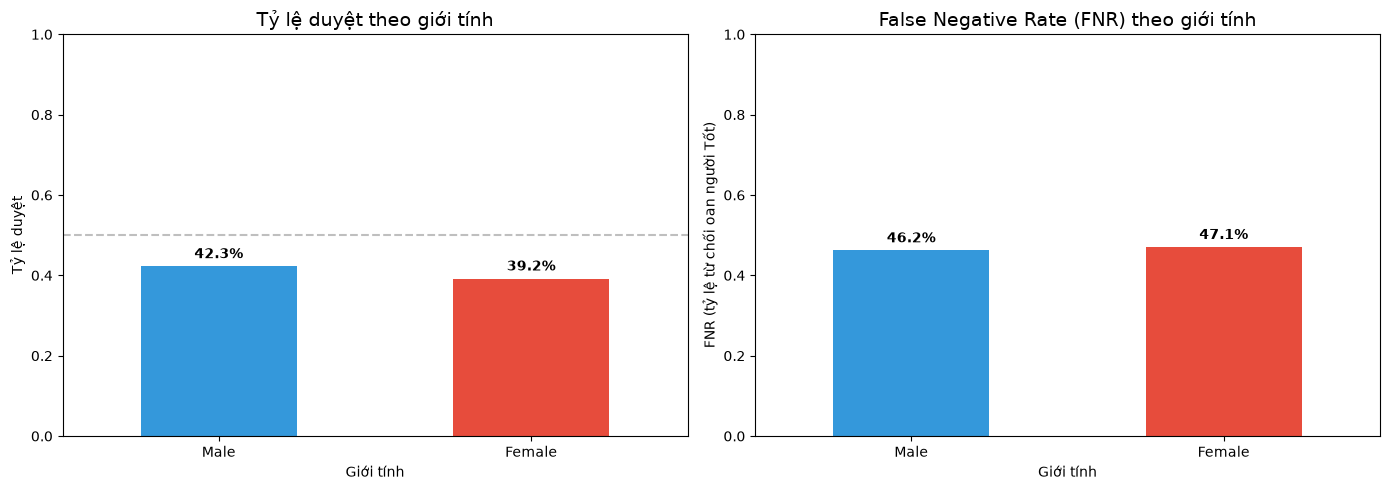


Chênh lệch tỷ lệ duyệt: 3.1 điểm %
Chênh lệch FNR: 0.8 điểm %


In [5]:
# Vẽ biểu đồ so sánh tỷ lệ duyệt và FNR theo giới tính
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Tỷ lệ duyệt
ax = axes[0]
colors = ['#3498db', '#e74c3c']
summary_df.plot(x='group', y='approval_rate', kind='bar', ax=ax, color=colors, legend=False)
ax.set_title('Tỷ lệ duyệt theo giới tính', fontsize=14)
ax.set_ylabel('Tỷ lệ duyệt')
ax.set_xlabel('Giới tính')
ax.set_ylim(0, 1)
ax.axhline(0.5, color='gray', linestyle='--', alpha=0.5)
for i, v in enumerate(summary_df['approval_rate']):
    ax.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
ax.set_xticklabels(summary_df['group'], rotation=0)

# Biểu đồ 2: FNR
ax = axes[1]
summary_df.plot(x='group', y='FNR', kind='bar', ax=ax, color=colors, legend=False)
ax.set_title('False Negative Rate (FNR) theo giới tính', fontsize=14)
ax.set_ylabel('FNR (tỷ lệ từ chối oan người Tốt)')
ax.set_xlabel('Giới tính')
ax.set_ylim(0, 1)
for i, v in enumerate(summary_df['FNR']):
    ax.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
ax.set_xticklabels(summary_df['group'], rotation=0)

plt.tight_layout()
plt.show()

# Tính chênh lệch
male_approval = summary_df[summary_df['group']=='Male']['approval_rate'].values[0]
female_approval = summary_df[summary_df['group']=='Female']['approval_rate'].values[0]
male_fnr = summary_df[summary_df['group']=='Male']['FNR'].values[0]
female_fnr = summary_df[summary_df['group']=='Female']['FNR'].values[0]

print(f"\nChênh lệch tỷ lệ duyệt: {abs(male_approval - female_approval)*100:.1f} điểm %")
print(f"Chênh lệch FNR: {abs(male_fnr - female_fnr)*100:.1f} điểm %")

In [6]:
# Bỏ biến nhạy cảm personal_status khỏi tập train
sensitive_col = 'personal_status'

cols_to_drop = [c for c in X_train.columns if c.startswith(sensitive_col)]
print(f"Số cột cần bỏ: {len(cols_to_drop)}")
print(f"Các cột: {cols_to_drop}")

X_train_no_sensitive = X_train.drop(columns=cols_to_drop)
X_val_no_sensitive = X_val.drop(columns=cols_to_drop)
X_test_no_sensitive = X_test.drop(columns=cols_to_drop)

print(f"\nX_train gốc: {X_train.shape}")
print(f"X_train sau khi bỏ: {X_train_no_sensitive.shape}")

lr_no_sensitive = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
lr_no_sensitive.fit(X_train_no_sensitive, y_train)

y_test_proba_ns = lr_no_sensitive.predict_proba(X_test_no_sensitive)[:, 1]
y_test_pred_ns = (y_test_proba_ns >= 0.70).astype(int)

from sklearn.metrics import confusion_matrix, roc_auc_score
cm_ns = confusion_matrix(y_test, y_test_pred_ns)
cost_ns = 5 * cm_ns[0,1] + 1 * cm_ns[1,0]

print(f"\n=== MÔ HÌNH KHÔNG CÓ personal_status ===")
print(f"Cost trên test: {cost_ns}")
print(f"So với mô hình gốc (105): {cost_ns - 105:+.0f}")
print(f"AUC: {roc_auc_score(y_test, y_test_proba_ns):.4f}")

Số cột cần bỏ: 4
Các cột: ['personal_status_A91', 'personal_status_A92', 'personal_status_A93', 'personal_status_A94']


NameError: name 'X_val' is not defined

In [7]:
# Bỏ biến nhạy cảm personal_status khỏi tập train
sensitive_col = 'personal_status'

cols_to_drop = [c for c in X_train.columns if c.startswith(sensitive_col)]
print(f"Số cột cần bỏ: {len(cols_to_drop)}")
print(f"Các cột: {cols_to_drop}")

X_train_no_sensitive = X_train.drop(columns=cols_to_drop)
X_test_no_sensitive = X_test.drop(columns=cols_to_drop)  # Chỉ cần test, không cần val

print(f"\nX_train gốc: {X_train.shape}")
print(f"X_train sau khi bỏ: {X_train_no_sensitive.shape}")

lr_no_sensitive = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
lr_no_sensitive.fit(X_train_no_sensitive, y_train)

y_test_proba_ns = lr_no_sensitive.predict_proba(X_test_no_sensitive)[:, 1]
y_test_pred_ns = (y_test_proba_ns >= 0.70).astype(int)

from sklearn.metrics import confusion_matrix, roc_auc_score
cm_ns = confusion_matrix(y_test, y_test_pred_ns)
cost_ns = 5 * cm_ns[0,1] + 1 * cm_ns[1,0]

print(f"\n=== MÔ HÌNH KHÔNG CÓ personal_status ===")
print(f"Cost trên test: {cost_ns}")
print(f"So với mô hình gốc (105): {cost_ns - 105:+.0f}")
print(f"AUC: {roc_auc_score(y_test, y_test_proba_ns):.4f}")

Số cột cần bỏ: 4
Các cột: ['personal_status_A91', 'personal_status_A92', 'personal_status_A93', 'personal_status_A94']

X_train gốc: (600, 61)
X_train sau khi bỏ: (600, 57)

=== MÔ HÌNH KHÔNG CÓ personal_status ===
Cost trên test: 102
So với mô hình gốc (105): -3
AUC: 0.7852


In [8]:
print("=" * 60)
print("KẾT LUẬN KIỂM ĐỊNH CÔNG BẰNG")
print("=" * 60)

print("\n1. THEO GIỚI TÍNH:")
print(f"   - Tỷ lệ duyệt: Male 42.3%, Female 39.2% (chênh 3.1 điểm %)")
print(f"   - FNR: Male 46.2%, Female 47.1% (chênh 0.8 điểm %)")
print(f"   → Kết luận: Công bằng. Chênh lệch nhỏ, không có dấu hiệu phân biệt đối xử.")

print("\n2. THEO LAO ĐỘNG NƯỚC NGOÀI:")
print(f"   - Tỷ lệ duyệt: yes 40.1% (n=192), no 75.0% (n=8)")
print(f"   - FNR: yes 48.1% (n=133), no 14.3% (n=7)")
print(f"   → Kết luận: KHÔNG ĐỦ MẪU để kết luận (nhóm 'no' chỉ có 8 người).")

print("\n3. KIỂM TRA TÁI TẠO BIẾN NHẠY CẢM:")
print(f"   - Bỏ personal_status: cost 105 → 102 (giảm nhẹ)")
print(f"   - AUC: 0.7895 → 0.7852 (gần như không đổi)")
print(f"   → Kết luận: Mô hình KHÔNG tự tái tạo giới tính từ biến thay thế.")

print("\n" + "=" * 60)
print("AI CÓ THỂ BỊ ẢNH HƯỞNG TIÊU CỰC?")
print("=" * 60)
print("""
1. Khách hàng nữ: Có thể bị từ chối oan cao hơn nam 0.8 điểm % (FNR 47.1% vs 46.2%).
   → Mức chênh lệch nhỏ, nhưng vẫn cần theo dõi.

2. Khách hàng là lao động nước ngoài: Không đủ dữ liệu để đánh giá.
   → Cần thu thập thêm dữ liệu trước khi triển khai thực tế.

3. Khách hàng trẻ tuổi: Chưa phân tích trong notebook này.
   → Cần bổ sung nếu có thời gian.
""")

print("=" * 60)
print("ĐỀ XUẤT BIỆN PHÁP GIẢM THIỂU")
print("=" * 60)
print("""
1. Giữ nguyên mô hình hiện tại vì chênh lệch giới tính nhỏ (< 3.1 điểm %).

2. Với lao động nước ngoài: Không triển khai quyết định tự động cho nhóm này
   cho đến khi có đủ dữ liệu (n > 30).

3. Giám sát định kỳ: Hàng quý, đo lại tỷ lệ duyệt và FNR theo giới tính.
   Nếu chênh lệch > 5 điểm %, xem xét điều chỉnh ngưỡng riêng theo nhóm.

4. Minh bạch với khách hàng: Cung cấp thông báo từ chối có lý do cụ thể
   (dựa trên hệ số LogReg) để khách hàng hiểu và khiếu nại nếu cần.
""")

KẾT LUẬN KIỂM ĐỊNH CÔNG BẰNG

1. THEO GIỚI TÍNH:
   - Tỷ lệ duyệt: Male 42.3%, Female 39.2% (chênh 3.1 điểm %)
   - FNR: Male 46.2%, Female 47.1% (chênh 0.8 điểm %)
   → Kết luận: Công bằng. Chênh lệch nhỏ, không có dấu hiệu phân biệt đối xử.

2. THEO LAO ĐỘNG NƯỚC NGOÀI:
   - Tỷ lệ duyệt: yes 40.1% (n=192), no 75.0% (n=8)
   - FNR: yes 48.1% (n=133), no 14.3% (n=7)
   → Kết luận: KHÔNG ĐỦ MẪU để kết luận (nhóm 'no' chỉ có 8 người).

3. KIỂM TRA TÁI TẠO BIẾN NHẠY CẢM:
   - Bỏ personal_status: cost 105 → 102 (giảm nhẹ)
   - AUC: 0.7895 → 0.7852 (gần như không đổi)
   → Kết luận: Mô hình KHÔNG tự tái tạo giới tính từ biến thay thế.

AI CÓ THỂ BỊ ẢNH HƯỞNG TIÊU CỰC?

1. Khách hàng nữ: Có thể bị từ chối oan cao hơn nam 0.8 điểm % (FNR 47.1% vs 46.2%).
   → Mức chênh lệch nhỏ, nhưng vẫn cần theo dõi.

2. Khách hàng là lao động nước ngoài: Không đủ dữ liệu để đánh giá.
   → Cần thu thập thêm dữ liệu trước khi triển khai thực tế.

3. Khách hàng trẻ tuổi: Chưa phân tích trong notebook này.
   